## 02-Fusion-融合

### 1. 是什么？
```
在多路召回之后，重排之前，将不同来源的文档列表进行融合，分数计算，重新排序
```

### 2. 要解决什么问题？
```
① 合并融合：将不同来源的检索结果进行融合
② 重新排名：跟问题相关性比较高的文档排在很后面
```

### 3. 基本思路


RAG 融合放在什么位置
```
向量召回 Top-30  ─┐
                 ├─ Fusion(RRF) → 候选 20–30 条 → Rerank → Top 3–5 → LLM
BM25 召回 Top-30 ┘
```


典型方法
```
① RRF (Reciprocal Rank Fusion, 倒数排名融合)
② Cohere Rerank
```

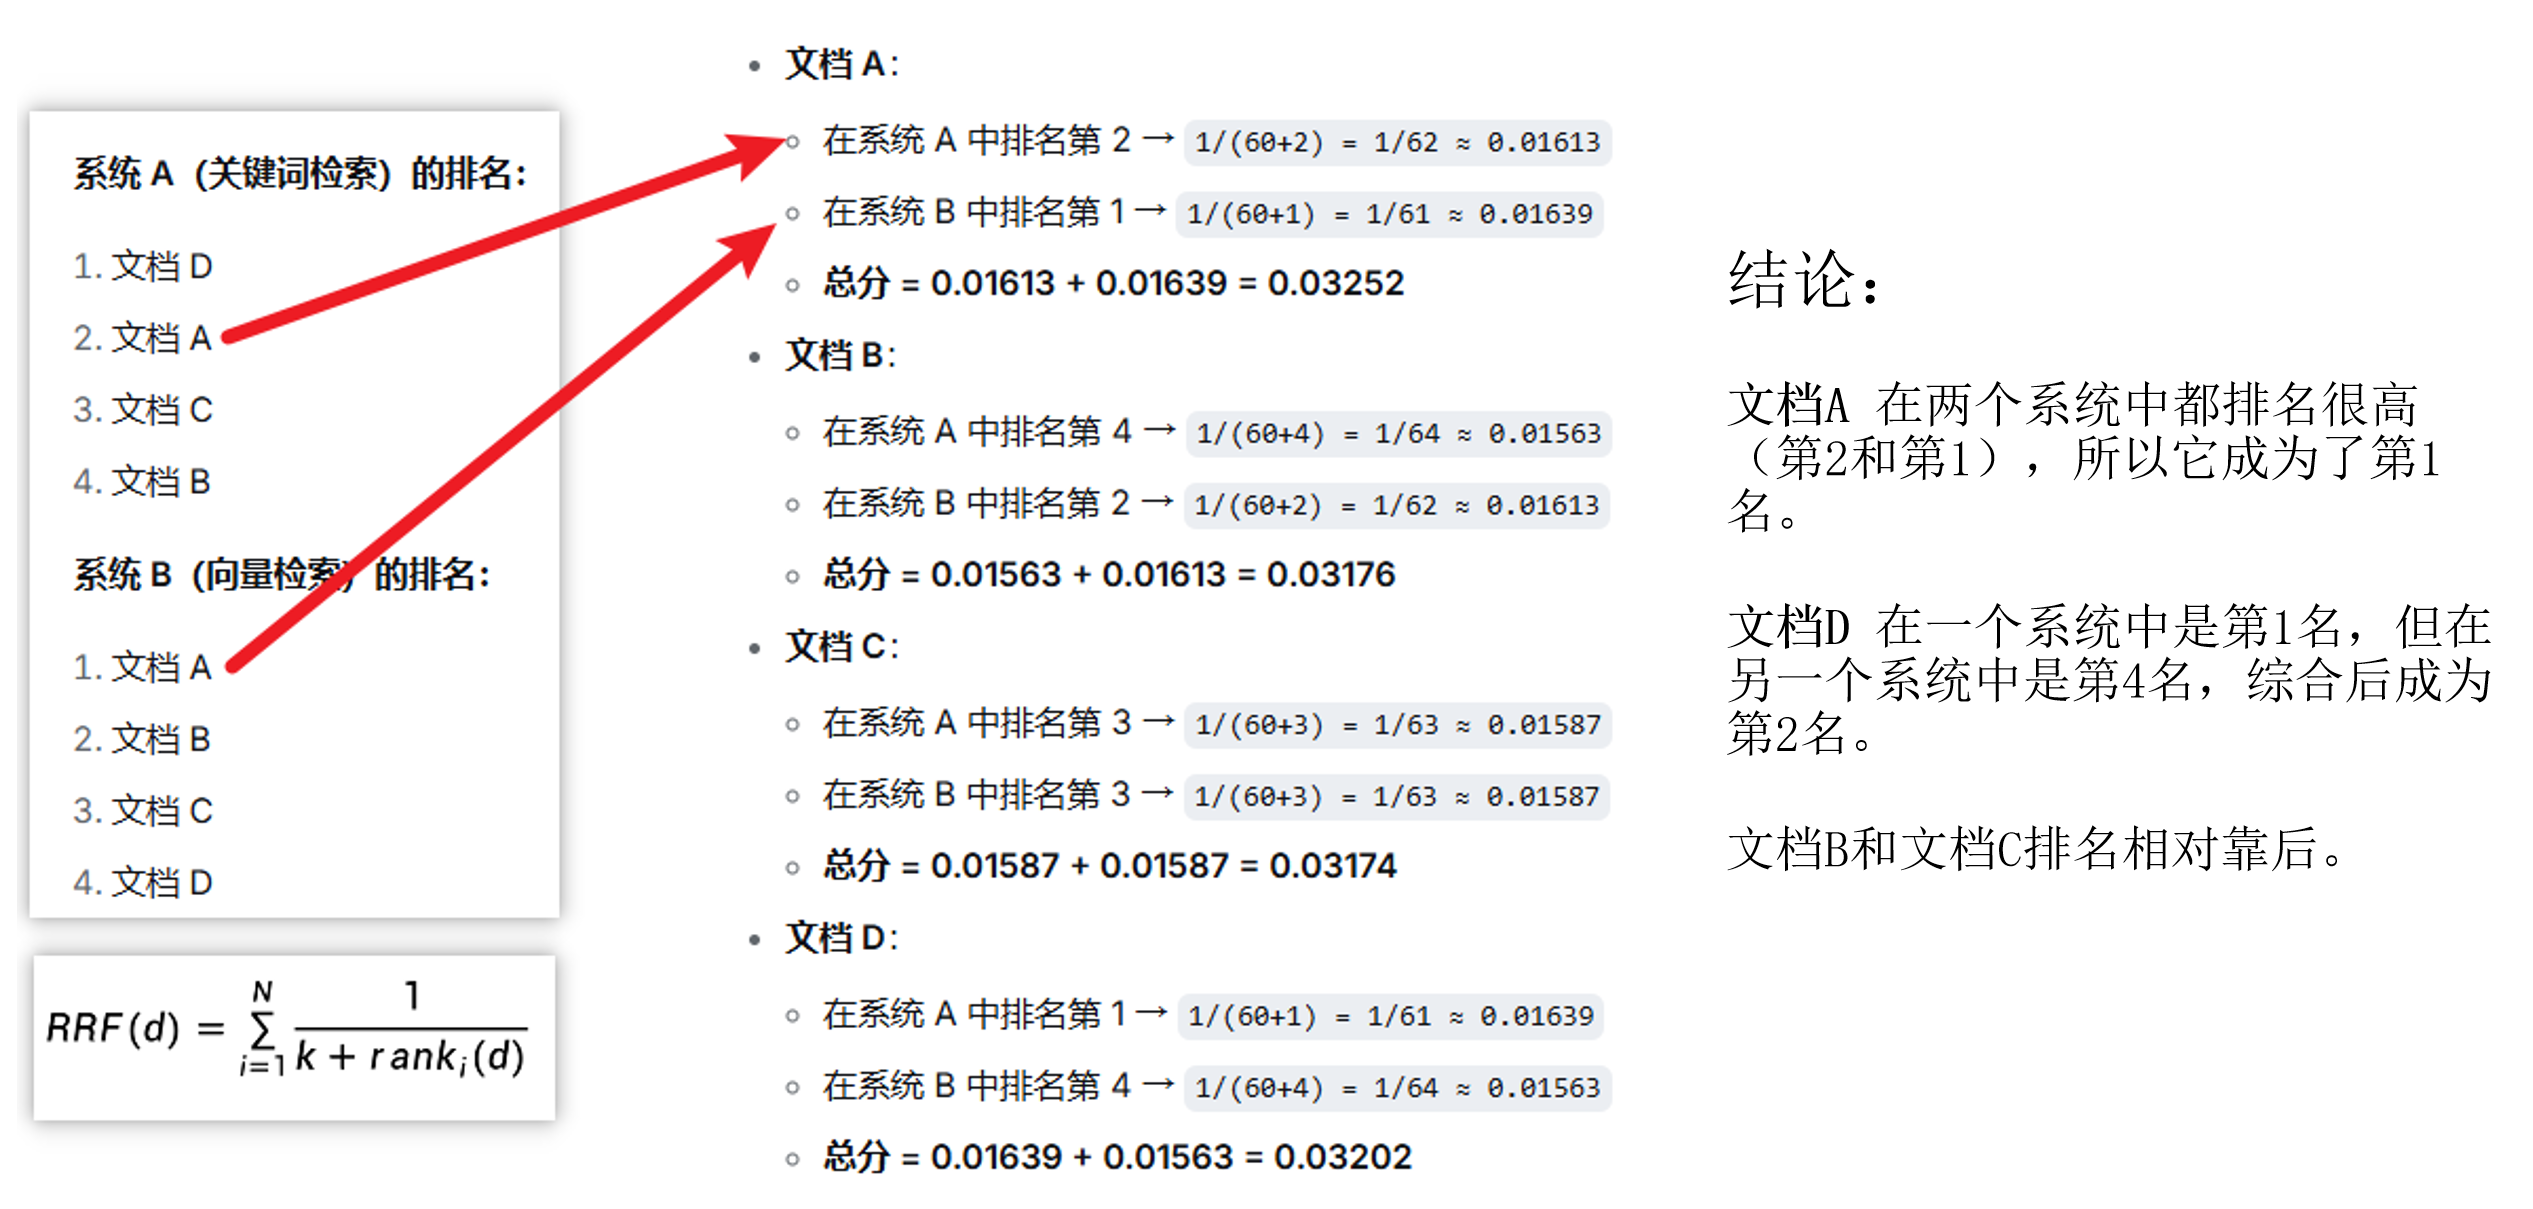

### 4. 代码实例

##### 对话模型

In [2]:
import os
from langchain_openai import ChatOpenAI
llm = deepseek = ChatOpenAI(api_key=os.getenv("DEEPSEEK_API_KEY"), model="deepseek-v4-flash", base_url="https://api.deepseek.com")

##### 嵌入模型

In [3]:
from langchain_community.embeddings import DashScopeEmbeddings
embeddings_model = DashScopeEmbeddings(model="text-embedding-v4", dashscope_api_key=os.getenv("DASHSCOPE_API_KEY"))

# 通过本地ollama上运行的bge-m3做向量化, 使用需要关闭 代理/VPN
from langchain_ollama import OllamaEmbeddings
embeddings_model = OllamaEmbeddings(model="bge-m3")

##### 文本准备

In [4]:
texts=[
    "人工智能在医疗诊断中的应用。",
    "人工智能如何提升供应链效率。",
    "NBA季后赛最新赛况分析。",
    "传统法式烘焙的五大技巧。",
    "红楼梦人物关系图谱分析。",
    "人工智能在金融风险管理中的应用。",
    "人工智能如何影响未来就业市场。",
    "人工智能在制造业的应用。",
    "今天天气怎么样",
    "人工智能伦理：公平性与透明度。"
]

##### VectorStore

In [5]:
from langchain_community.vectorstores import Chroma
vectorstore = Chroma.from_texts(texts=texts, embedding= embeddings_model)
retriever = vectorstore.as_retriever()

##### 多路查询

In [6]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate

multi_query_prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a helpful assistant that generates multiple search queries based on a single input query."),
    ("user", "Generate multiple search queries related to: {original_query}"),
    ("user", "OUTPUT (4 queries):")
])

multi_query_chain = (
    multi_query_prompt | llm | StrOutputParser() | (lambda x: x.split("\n"))
)

original_query = "人工智能的应用"
multi_queries = multi_query_chain.invoke({"original_query": original_query})
print(f"原始查询：{original_query}\n生成的查询：{multi_queries}")

原始查询：人工智能的应用
生成的查询：['1. 人工智能的应用领域有哪些  ', '2. 人工智能在医疗、教育、金融等行业的应用案例  ', '3. 2025年人工智能应用趋势与典型场景  ', '4. 企业如何落地人工智能应用场景与实践案例']


In [15]:
#Post-Retrieval后检索-重排序RAG-Fusion
from langchain_classic.load import dumps,loads

def reciprocal_rank_fusion(results: list[list], k=60):
    """互逆排序融合算法，用于合并多个排序文档列表
    Args:
        results: 包含多个排序文档列表的二维列表
        k: 融合公式中的平滑参数（默认60），值越小排名影响越大
    RRF 分数计算:
    假设我们有两个查询的检索结果:
        results = [
        [doc1, doc2, doc3],  # 第一个查询的结果
        [doc2, doc4, doc1]   # 第二个查询的结果
        ]
        k = 60
        在遍历过程中，doc1 在第一个查询中排名第 0，在第二个查询中排名第 2，它的 RRF 分数计算如下：

        第一个查询：1 / (0 + 60) = 1/60
        第二个查询：1 / (2 + 60) = 1/62
        累计分数：1/60 + 1/62
    通过这种方式，每个文档都会根据其在各个查询结果中的排名获得一个综合的分数，最终根据这个分数进行降序排序，得到融合后的结果。
    Returns:
        按融合分数降序排列的文档列表，每个元素为(文档对象, 分数)元组
    """
    # 初始化融合分数字典（key=序列化文档，value=累计分数）
    fused_scores = {}

    # 遍历每个检索结果列表（每个查询对应的结果）
    for docs in results:
        # 对当前结果列表中的文档进行遍历（rank从0开始计算）
        for rank, doc in enumerate(docs,1):
            # 序列化文档对象为字符串（用于唯一标识）
            doc_str = dumps(doc)
            # 初始化文档得分（如果是首次出现）
            if doc_str not in fused_scores:
                fused_scores[doc_str] = 0
            # 计算并累加RRF分数：1 / (当前排名 + k)
            # 排名越靠前（rank值小）的文档获得的分数越高

            fused_scores[doc_str] += 1 / (rank + k)

    # 按融合分数降序排序（分数越高排名越前） 生成按相关度从高到低排列的文档列表。
    reranked_results = [
        (loads(doc), score)  # 反序列化还原文档对象
        # sorted 对 fused_scores 字典进行排序
        # fused_scores.items() 返回键值对列表 [(doc_str1, score1), (doc_str2, score2), ...]
        # key=lambda x: x[1] 指定按分数（元组的第二个元素）排序
        # reverse=True 降序排序 （分数高的在前）
        for doc, score in sorted(fused_scores.items(),
                               key=lambda x: x[1], # 取分数
                               reverse=True)
    ]
    # print(reranked_results)
    return reranked_results


'''
multi_query_chain会生成4个多角度的query,
retriever.map()的作用是根据multi_query_chain的结果映射出4个retriever(可以理解为同时复制出4个retriever), 与multi_query_chain生成的4个query对应，
并为每个query检索出来的一组相关文档集(默认为4个相关文档)，
那么4个query总共可以生成16个相关文档。
最后会经过RRF算法重新排序后输出最相关的文档
'''
chain = multi_query_chain | retriever.map() | reciprocal_rank_fusion

original_query = "人工智能的应用"
result_list = chain.invoke({"original_query": original_query})
print("--"*15, '输出重排结果列表：\n',result_list)


# 提取文档内容和对应分数
contents = [doc[0].page_content for doc in result_list]
scores = [doc[1] for doc in result_list]
combined_tuples = list(zip(contents, scores))
print("--"*15,"最相关的文档及其得分：")
for item in combined_tuples:
    print(item)

------------------------------ 输出重排结果列表：
 [(Document(metadata={}, page_content='人工智能在制造业的应用。'), 0.06557377049180328), (Document(metadata={}, page_content='人工智能在金融风险管理中的应用。'), 0.06400409626216078), (Document(metadata={}, page_content='人工智能如何影响未来就业市场。'), 0.06274801587301587), (Document(metadata={}, page_content='人工智能在医疗诊断中的应用。'), 0.04788306451612903), (Document(metadata={}, page_content='人工智能如何提升供应链效率。'), 0.015873015873015872)]
------------------------------ 最相关的文档及其得分：
('人工智能在制造业的应用。', 0.06557377049180328)
('人工智能在金融风险管理中的应用。', 0.06400409626216078)
('人工智能如何影响未来就业市场。', 0.06274801587301587)
('人工智能在医疗诊断中的应用。', 0.04788306451612903)
('人工智能如何提升供应链效率。', 0.015873015873015872)


C:\Users\user\AppData\Local\Temp\ipykernel_48644\1146247878.py:44: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit list of allowed classes (or 'messages' for untrusted input that contains only chat messages) to suppress this warning.
  (loads(doc), score)  # 反序列化还原文档对象


In [16]:
print("--"*15,"分析一下这些分数是如何统计出来的：")
#分析一下这些分数是如何统计出来的
chain1 = multi_query_chain | retriever.map()
chain1_result = chain1.invoke({"original_query": original_query})

#原始输出是一个二维列表，每个元素是由4个query生成的Document列表
print("--"*15)
print(chain1_result)

# 处理输出格式
contents = [doc.page_content
            for group in chain1_result  # 遍历外层列表
            for doc in group]        # 遍历内层文档列表
print("--"*15)
print(contents)


------------------------------ 分析一下这些分数是如何统计出来的：
------------------------------
[[Document(metadata={}, page_content='人工智能在制造业的应用。'), Document(metadata={}, page_content='人工智能在金融风险管理中的应用。'), Document(metadata={}, page_content='人工智能在医疗诊断中的应用。'), Document(metadata={}, page_content='人工智能如何影响未来就业市场。')], [Document(metadata={}, page_content='人工智能在医疗诊断中的应用。'), Document(metadata={}, page_content='人工智能在制造业的应用。'), Document(metadata={}, page_content='人工智能在金融风险管理中的应用。'), Document(metadata={}, page_content='人工智能如何影响未来就业市场。')], [Document(metadata={}, page_content='人工智能在制造业的应用。'), Document(metadata={}, page_content='人工智能在医疗诊断中的应用。'), Document(metadata={}, page_content='人工智能在金融风险管理中的应用。'), Document(metadata={}, page_content='人工智能如何影响未来就业市场。')], [Document(metadata={}, page_content='人工智能在金融风险管理中的应用。'), Document(metadata={}, page_content='人工智能在制造业的应用。'), Document(metadata={}, page_content='人工智能在医疗诊断中的应用。'), Document(metadata={}, page_content='人工智能如何影响未来就业市场。')]]
------------------------------
['人工智能在制造业的应